# 🎓 Fine-Tuning, Visualised — a hands-on lab (Google Colab · A100)

This notebook teaches model fine-tuning by **doing it and watching it happen**. Every stage has plots so you can *see* what changes inside a model when you fine-tune it.

| Part | What you'll learn | Model | ~Time on A100 |
|---|---|---|---|
| 0 | Setup & GPU check | – | 1–2 min |
| 1 | Data, tokenization, train/val/test splits | – | 1 min |
| 2 | **Full fine-tuning** (every weight updated) + what changed inside the model | DistilBERT (66M) | 2–3 min |
| 3 | **LoRA** (parameter-efficient fine-tuning) and why it works | DistilBERT + LoRA | 2 min |
| 4 | Hyperparameter lab: learning rate, LoRA rank, **overfitting** | DistilBERT + LoRA | 3–4 min |
| 5 | **Fine-tuning an LLM** (instruction / SFT) with LoRA: chat templates, loss masking, before vs after, forgetting | Qwen2.5-0.5B-Instruct | 4–6 min |
| 6 | Summary & next steps | – | – |

**Total: ~15–20 minutes** (most of the variance is model downloads).

**Runtime settings:** Python 3 · A100 GPU · High-RAM *off* is fine · Runtime version: Latest.

Run cells **top to bottom** (`Runtime → Run all` works too). Nothing needs a Hugging Face login.

---
### The big picture in one paragraph
A *pre-trained* model has already learned general knowledge (grammar, facts, patterns) from huge amounts of data. **Fine-tuning** continues training that model on a *small, task-specific* dataset so it becomes good at *your* task. It's cheap compared to pre-training because the model starts from a good place — you're nudging the weights, not learning from scratch. The key questions are: *which* weights to update (all of them? a tiny adapter?), *how fast* (learning rate), *how long* (epochs / overfitting), and *on what data* (format, masking).

## Part 0 — Setup
Colab already ships PyTorch, 🤗 Transformers, Datasets, scikit-learn and matplotlib. We add **PEFT** (the library that implements LoRA) if it's missing.

In [ ]:
!pip install -q peft datasets accelerate
!nvidia-smi --query-gpu=name,memory.total,memory.used --format=csv

name, memory.total [MiB], memory.used [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB, 0 MiB


In [ ]:
import os, re, gc, json, math, time, html, random, warnings, contextlib, collections
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, display

import transformers, peft, datasets
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, AutoModelForCausalLM,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup,
                          get_cosine_schedule_with_warmup)
from transformers.utils import logging as hf_logging
from peft import LoraConfig, get_peft_model, TaskType
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")
hf_logging.set_verbosity_error()
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

assert torch.cuda.is_available(), "No GPU found → Runtime ▸ Change runtime type ▸ A100 GPU"
device = "cuda"
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# Mixed precision: weights stay in fp32 (stable optimiser maths), the forward pass runs in bfloat16 (fast).
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else None
def autocast():
    return torch.autocast("cuda", dtype=AMP_DTYPE) if AMP_DTYPE else contextlib.nullcontext()

NOTEBOOK_START = time.time()
def elapsed():
    print(f"⏱  {(time.time() - NOTEBOOK_START) / 60:.1f} min since the notebook started")

print(f"GPU: {torch.cuda.get_device_name(0)}  |  VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.0f} GB  |  bf16: {AMP_DTYPE is not None}")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | peft {peft.__version__} | datasets {datasets.__version__}")

GPU: NVIDIA A100-SXM4-40GB  |  VRAM: 42 GB  |  bf16: True
torch 2.11.0+cu130 | transformers 5.21.0 | peft 0.21.2 | datasets 4.8.5


### Shared helpers
One **generic training loop** is used for every experiment in this notebook, so you can read it once and understand all of them. It's deliberately written by hand (no `Trainer`) so nothing is hidden:

1. forward pass → loss  2. `loss.backward()` → gradients  3. clip gradients  4. optimiser step  5. learning-rate scheduler step  6. log everything.

In [ ]:
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return trainable, total

def ema(xs, alpha=0.9):
    """Exponential moving average — smooths noisy per-step loss curves."""
    out, v = [], None
    for x in xs:
        v = x if v is None or not np.isfinite(v) else alpha * v + (1 - alpha) * x
        out.append(v)
    return out

def free_gpu(*names):
    for n in names:
        globals().pop(n, None)
    gc.collect(); torch.cuda.empty_cache()

def train(model, train_loader, eval_fn, epochs, lr, weight_decay=0.01, warmup_ratio=0.1,
          schedule="linear", eval_every=50, verbose=True, desc=""):
    """Generic fine-tuning loop. Returns a history dict with everything we want to plot."""
    params = [p for p in model.parameters() if p.requires_grad]          # only trainable weights!
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    total = epochs * len(train_loader)
    make_sched = get_cosine_schedule_with_warmup if schedule == "cosine" else get_linear_schedule_with_warmup
    sched = make_sched(opt, int(warmup_ratio * total), total)

    hist = dict(step=[], loss=[], lr=[], grad_norm=[], eval_step=[], val_loss=[], val_acc=[])
    step, t0 = 0, time.time()
    for ep in range(epochs):
        model.train()
        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            with autocast():
                loss = model(**batch).loss                               # 1. forward
            loss.backward()                                              # 2. backward
            gn = torch.nn.utils.clip_grad_norm_(params, 1.0)             # 3. clip
            opt.step(); sched.step(); opt.zero_grad(set_to_none=True)    # 4-5. update
            step += 1
            hist["step"].append(step); hist["loss"].append(loss.item())  # 6. log
            hist["lr"].append(sched.get_last_lr()[0]); hist["grad_norm"].append(gn.item())
            if step % eval_every == 0 or step == total:
                r = eval_fn(model); model.train()
                hist["eval_step"].append(step); hist["val_loss"].append(r["loss"])
                hist["val_acc"].append(r.get("acc", float("nan")))
                if verbose:
                    msg = f"[{desc}] ep {ep+1} step {step:4d}/{total} | train loss {np.mean(hist['loss'][-eval_every:]):.4f} | val loss {r['loss']:.4f}"
                    if "acc" in r: msg += f" | val acc {r['acc']:.3f}"
                    print(msg)
    hist["time"] = time.time() - t0
    return hist

def plot_history(hist, title):
    has_acc = not np.all(np.isnan(hist["val_acc"]))
    fig, ax = plt.subplots(1, 4, figsize=(21, 4))
    ax[0].plot(hist["step"], hist["loss"], alpha=0.25, label="train (per step)")
    ax[0].plot(hist["step"], ema(hist["loss"]), label="train (smoothed)")
    ax[0].plot(hist["eval_step"], hist["val_loss"], "o-", label="validation")
    ax[0].set_title("Loss ↓"); ax[0].set_xlabel("step"); ax[0].legend()
    if has_acc:
        ax[1].plot(hist["eval_step"], hist["val_acc"], "o-", color="green"); ax[1].set_title("Validation accuracy ↑")
    else:
        ax[1].plot(hist["eval_step"], np.exp(hist["val_loss"]), "o-", color="green"); ax[1].set_title("Validation perplexity = e^loss ↓")
    ax[1].set_xlabel("step")
    ax[2].plot(hist["step"], hist["lr"], color="purple"); ax[2].set_title("Learning rate (warm-up → decay)"); ax[2].set_xlabel("step")
    ax[3].plot(hist["step"], hist["grad_norm"], alpha=0.3, color="orange"); ax[3].plot(hist["step"], ema(hist["grad_norm"]), color="red")
    ax[3].axhline(1.0, ls="--", c="gray", lw=1); ax[3].set_title("Gradient norm (dashed = clip at 1.0)"); ax[3].set_xlabel("step")
    fig.suptitle(f"{title}  —  {hist['time']:.0f}s", fontsize=14, y=1.03); plt.tight_layout(); plt.show()

RESULTS = {}   # filled in as we go, compared at the end

## Part 1 — The data
We'll fine-tune on **`dair-ai/emotion`**: ~16k English tweets, each labelled with one of 6 emotions. It's small enough to train in seconds on an A100, but hard enough that fine-tuning clearly matters.

Every fine-tuning project needs three splits:
- **train** — what the model learns from
- **validation** — what *you* watch while training (to pick hyperparameters, spot overfitting)
- **test** — touched once at the end for an honest score

In [ ]:
try:
    emotion = load_dataset("dair-ai/emotion")
except Exception as e:
    print("Primary dataset id failed, trying fallback:", e)
    emotion = load_dataset("emotion")

LABELS = emotion["train"].features["label"].names
NUM_LABELS = len(LABELS)
print(emotion)
df_train = emotion["train"].to_pandas()
df_train.assign(label_name=df_train.label.map(lambda i: LABELS[i])).sample(8, random_state=1)

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


,text,label,label_name
2990,i am going to post my training schedule for th...,1,joy
13607,i start to feel like im getting over the death...,2,love
10421,i still feel incredibly listless being in albu...,0,sadness
6238,i can remember i feel especially impressed to ...,5,surprise
6790,i actually prefer peep toe shoes because of it...,5,surprise
8729,during the weekend at home,3,anger
5350,i cant even remember what it feels like to be ...,2,love
1217,i want to say that i feel vulnerable writing a...,4,fear


### Tokenization — how text becomes numbers
Models don't see words, they see **token IDs**. A tokenizer splits text into sub-word pieces from a fixed vocabulary. Rare words get split into several pieces (`##` marks a continuation). We also need a **max length**: shorter batches = faster training, but too short cuts off text.

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Text   : i feel absolutely unbelievably wonderful about finetuning today
Tokens : ['[CLS]', 'i', 'feel', 'absolutely', 'un', '##bel', '##ie', '##va', '##bly', 'wonderful', 'about', 'fine', '##tu', '##ning', 'today', '[SEP]']
IDs    : [101, 1045, 2514, 7078, 4895, 8671, 2666, 3567, 6321, 6919, 2055, 2986, 8525, 5582, 2651, 102]
[CLS] starts every sequence — its final hidden state is what the classifier reads. [SEP] ends it.


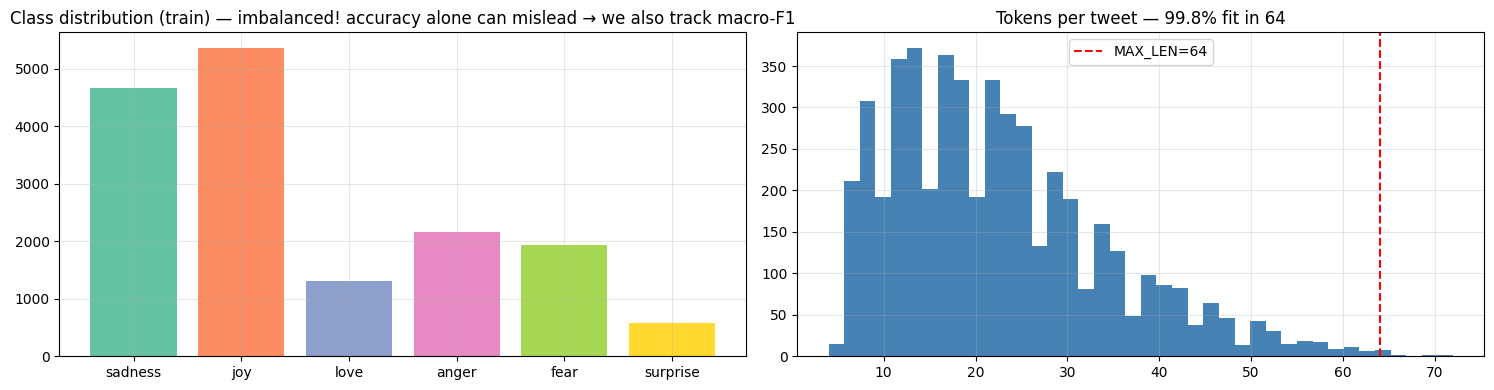

In [ ]:
CLS_MODEL = "distilbert-base-uncased"
cls_tok = AutoTokenizer.from_pretrained(CLS_MODEL)

example = "i feel absolutely unbelievably wonderful about finetuning today"
enc = cls_tok(example)
print("Text   :", example)
print("Tokens :", cls_tok.convert_ids_to_tokens(enc["input_ids"]))
print("IDs    :", enc["input_ids"])
print("[CLS] starts every sequence — its final hidden state is what the classifier reads. [SEP] ends it.")

MAX_LEN = 64
tok_lens = [len(x) for x in cls_tok(df_train.text.tolist()[:5000])["input_ids"]]

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
counts = df_train.label.value_counts().sort_index()
ax[0].bar([LABELS[i] for i in counts.index], counts.values, color=sns.color_palette("Set2", NUM_LABELS))
ax[0].set_title("Class distribution (train) — imbalanced! accuracy alone can mislead → we also track macro-F1")
ax[1].hist(tok_lens, bins=40, color="steelblue"); ax[1].axvline(MAX_LEN, c="red", ls="--", label=f"MAX_LEN={MAX_LEN}")
ax[1].set_title(f"Tokens per tweet — {np.mean(np.array(tok_lens) <= MAX_LEN):.1%} fit in {MAX_LEN}"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
def _tok(batch):
    return cls_tok(batch["text"], truncation=True, max_length=MAX_LEN)

emotion_tok = emotion.map(_tok, batched=True, remove_columns=["text"]).rename_column("label", "labels")
collator = DataCollatorWithPadding(cls_tok)   # pads each batch to its own longest sequence (dynamic padding)

def make_loader(split, batch_size=64, shuffle=False, n=None):
    d = emotion_tok[split]
    if n is not None:
        d = d.shuffle(seed=SEED).select(range(min(n, len(d))))
    return DataLoader(d, batch_size=batch_size, shuffle=shuffle, collate_fn=collator)

train_loader = make_loader("train", 64, shuffle=True)
val_loader   = make_loader("validation", 256)
test_loader  = make_loader("test", 256)
viz_loader   = make_loader("test", 256, n=1500)        # subset used for pictures
val_small    = make_loader("validation", 256, n=1000)  # fast eval for the hyperparameter lab

b = next(iter(train_loader))
print({k: tuple(v.shape) for k, v in b.items()})
print("attention_mask marks real tokens (1) vs padding (0):\n", b["attention_mask"][0].tolist())

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

{'labels': (64,), 'input_ids': (64, 59), 'token_type_ids': (64, 59), 'attention_mask': (64, 59)}
attention_mask marks real tokens (1) vs padding (0):
 [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## Part 2 — Full fine-tuning
We take a pre-trained DistilBERT, bolt a **new, randomly initialised classification head** on top (768 → 6 classes), and train **all 66M weights**.

Before training, let's measure it. The head is random, so accuracy should be near chance (1/6 ≈ 17%) — the body *understands* English, but nothing connects that understanding to our labels yet.

In [ ]:
@torch.no_grad()
def evaluate_cls(model, loader, return_emb=False):
    model.eval()
    preds, labels, embs, loss_sum, n = [], [], [], 0.0, 0
    for b in loader:
        b = {k: v.to(device) for k, v in b.items()}
        with autocast():
            out = model(**b, output_hidden_states=return_emb)
        bs = b["labels"].size(0); loss_sum += out.loss.float().item() * bs; n += bs
        preds.append(out.logits.argmax(-1).cpu()); labels.append(b["labels"].cpu())
        if return_emb:
            embs.append(out.hidden_states[-1][:, 0].float().cpu())   # the [CLS] vector
    preds, labels = torch.cat(preds), torch.cat(labels)
    r = dict(loss=loss_sum / n, acc=(preds == labels).float().mean().item(),
             f1=f1_score(labels, preds, average="macro"), preds=preds, labels=labels)
    if return_emb:
        r["emb"] = torch.cat(embs)
    return r

def make_cls_model():
    set_seed()
    m = AutoModelForSequenceClassification.from_pretrained(
        CLS_MODEL, num_labels=NUM_LABELS,
        id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)})
    return m.float().to(device)

full_model = make_cls_model()
tr, tot = count_params(full_model)
print(f"Trainable params: {tr:,} / {tot:,} ({tr/tot:.0%})")

before_full = evaluate_cls(full_model, viz_loader, return_emb=True)
print(f"BEFORE fine-tuning → accuracy {before_full['acc']:.3f}  (chance ≈ {1/NUM_LABELS:.3f})")

# Snapshot of every weight, so we can measure what fine-tuning changed
init_state = {k: v.detach().cpu().clone() for k, v in full_model.state_dict().items()}

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Trainable params: 66,958,086 / 66,958,086 (100%)
BEFORE fine-tuning → accuracy 0.134  (chance ≈ 0.167)


### Train it
Typical full fine-tuning recipe: **AdamW, lr = 5e-5** (small! big steps would wreck the pre-trained knowledge), 10% warm-up then linear decay, 2 epochs.

Watch the four panels after training:
- **Loss** falls fast at first (the head learns quickly), then slowly.
- **Learning rate** ramps up (warm-up protects the pre-trained weights from big early, noisy updates) then decays.
- **Gradient norm** is large at the start, then settles.

[Full FT] ep 1 step   50/500 | train loss 1.5932 | val loss 1.1665 | val acc 0.581
[Full FT] ep 1 step  100/500 | train loss 0.7861 | val loss 0.4257 | val acc 0.864
[Full FT] ep 1 step  150/500 | train loss 0.3746 | val loss 0.2652 | val acc 0.917
[Full FT] ep 1 step  200/500 | train loss 0.2650 | val loss 0.2110 | val acc 0.920
[Full FT] ep 1 step  250/500 | train loss 0.2322 | val loss 0.1736 | val acc 0.934
[Full FT] ep 2 step  300/500 | train loss 0.1508 | val loss 0.1741 | val acc 0.929
[Full FT] ep 2 step  350/500 | train loss 0.1518 | val loss 0.1759 | val acc 0.935
[Full FT] ep 2 step  400/500 | train loss 0.1443 | val loss 0.1556 | val acc 0.933
[Full FT] ep 2 step  450/500 | train loss 0.1262 | val loss 0.1543 | val acc 0.931
[Full FT] ep 2 step  500/500 | train loss 0.1507 | val loss 0.1448 | val acc 0.935

TEST accuracy 0.928 | macro-F1 0.881


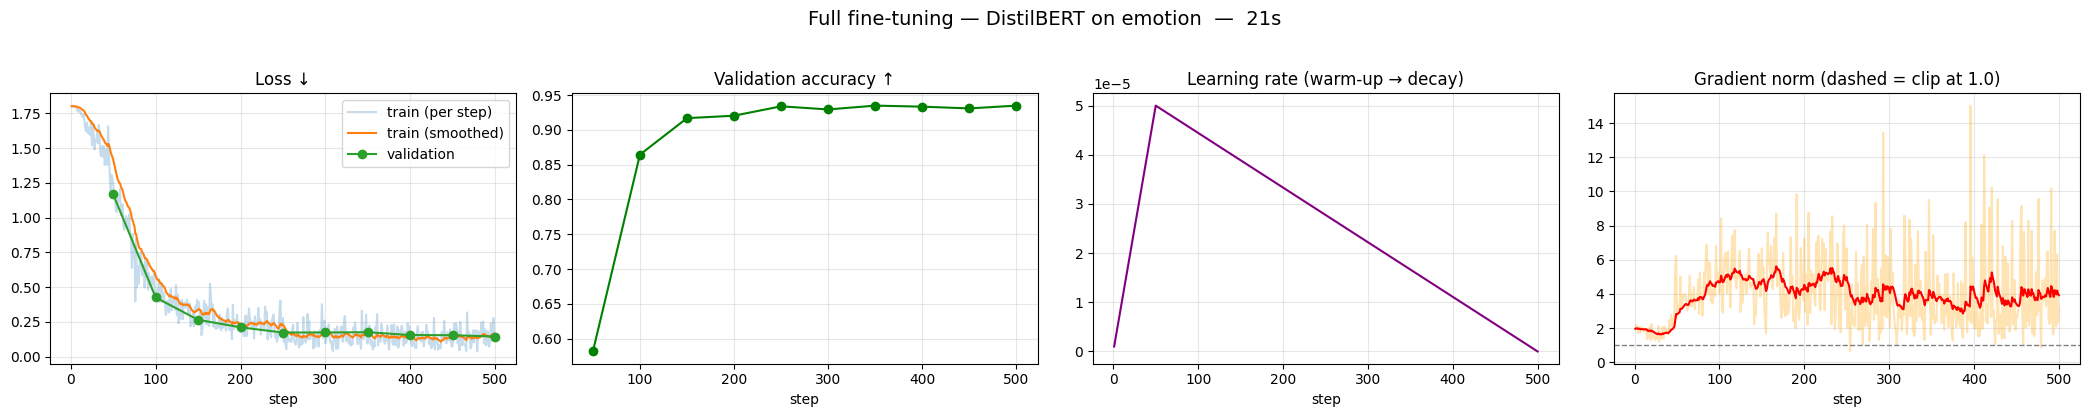

⏱  1.7 min since the notebook started


In [ ]:
torch.cuda.reset_peak_memory_stats()
hist_full = train(full_model, train_loader, lambda m: evaluate_cls(m, val_loader),
                  epochs=2, lr=5e-5, eval_every=50, desc="Full FT")
test_full = evaluate_cls(full_model, test_loader)
RESULTS["Full fine-tune"] = dict(trainable=tr, total=tot, time_s=hist_full["time"],
                                 peak_mem_gb=torch.cuda.max_memory_allocated() / 1e9,
                                 test_acc=test_full["acc"], test_f1=test_full["f1"])
print(f"\nTEST accuracy {test_full['acc']:.3f} | macro-F1 {test_full['f1']:.3f}")
plot_history(hist_full, "Full fine-tuning — DistilBERT on emotion")
elapsed()

### What did fine-tuning change? (1) Predictions
Confusion matrices: rows = true label, columns = prediction. Before: random guesses. After: a strong diagonal. Off-diagonal cells show which emotions the model still confuses (often *joy ↔ love* and *anger ↔ fear*, which genuinely overlap).

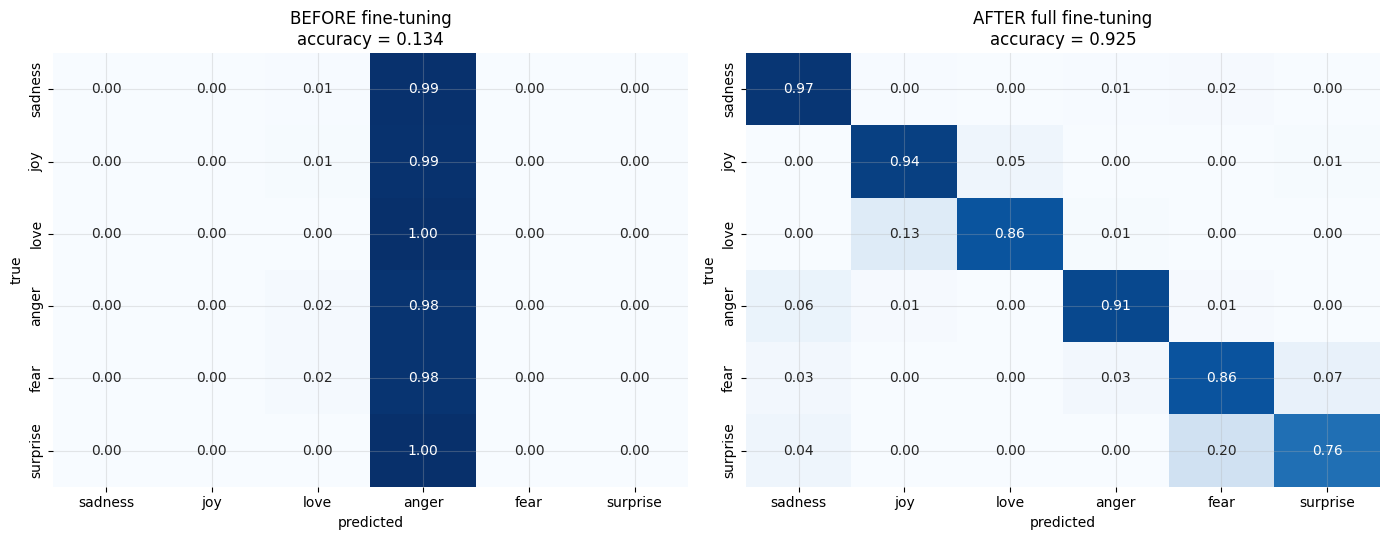

In [ ]:
after_full = evaluate_cls(full_model, viz_loader, return_emb=True)

def plot_confusions(results, titles):
    fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 5.5))
    for ax, r, t in zip(np.atleast_1d(axes), results, titles):
        cm = confusion_matrix(r["labels"], r["preds"], labels=range(NUM_LABELS), normalize="true")
        sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                    xticklabels=LABELS, yticklabels=LABELS, ax=ax, cbar=False)
        ax.set_title(f"{t}\naccuracy = {r['acc']:.3f}"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    plt.tight_layout(); plt.show()

plot_confusions([before_full, after_full], ["BEFORE fine-tuning", "AFTER full fine-tuning"])

### What did fine-tuning change? (2) The model's internal representation
Each tweet becomes a 768-dimensional `[CLS]` vector. We squash those to 2D with t-SNE and colour by the *true* label.

- **Before:** the pre-trained model groups tweets by general meaning/topic — emotions are mixed together.
- **After:** the model has *reorganised its internal space* so each emotion forms its own cluster. This is the real effect of fine-tuning: not just a new head, but a re-shaped representation.

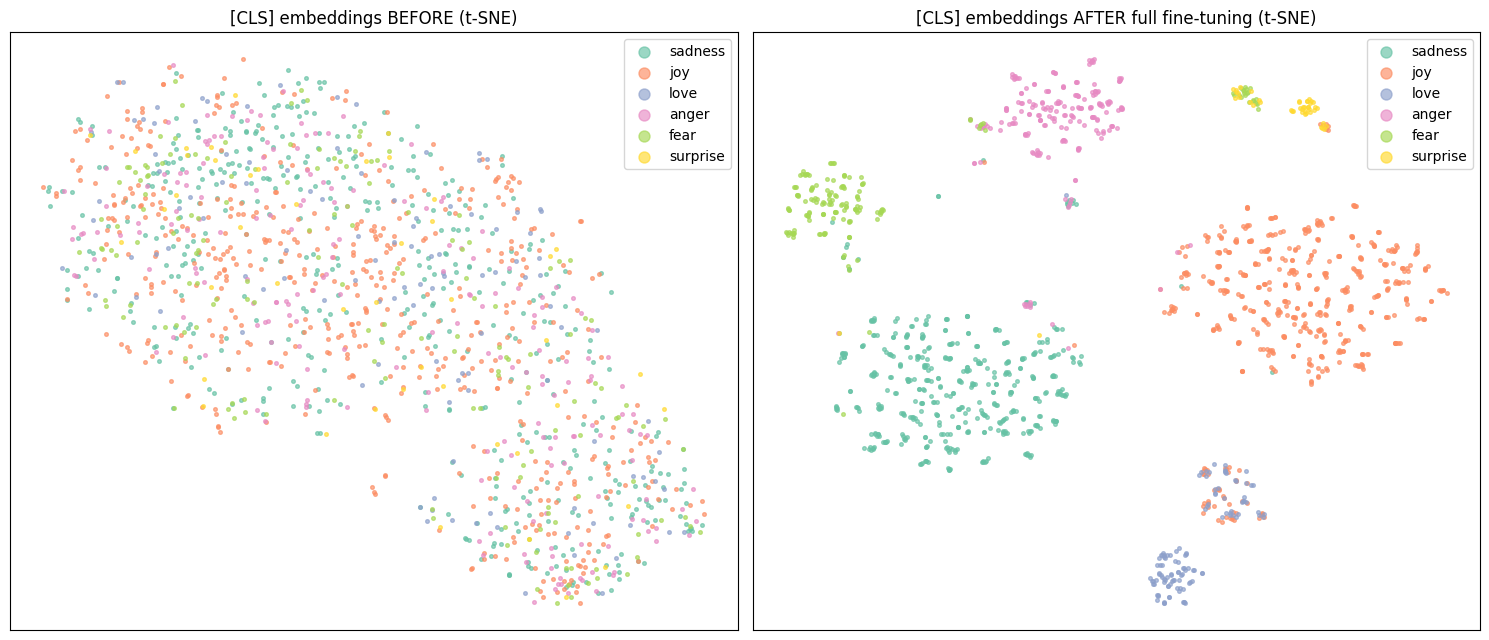

In [ ]:
def plot_embeddings(results, titles):
    fig, axes = plt.subplots(1, len(results), figsize=(7.5 * len(results), 6.5))
    pal = sns.color_palette("Set2", NUM_LABELS)
    for ax, r, t in zip(np.atleast_1d(axes), results, titles):
        xy = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED).fit_transform(r["emb"].numpy())
        lab = r["labels"].numpy()
        for i, l in enumerate(LABELS):
            m = lab == i
            ax.scatter(xy[m, 0], xy[m, 1], s=7, alpha=0.65, color=pal[i], label=l)
        ax.set_title(t); ax.set_xticks([]); ax.set_yticks([]); ax.legend(markerscale=3, loc="best")
    plt.tight_layout(); plt.show()

plot_embeddings([before_full, after_full], ["[CLS] embeddings BEFORE (t-SNE)", "[CLS] embeddings AFTER full fine-tuning (t-SNE)"])

### What did fine-tuning change? (3) The weights themselves
For each part of the network we compute the **relative weight change** ‖W_after − W_before‖ / ‖W_before‖.

Things to notice:
- The changes to the pre-trained body are **tiny** (well under a few %). Fine-tuning *nudges*, it doesn't rewrite.
- **Later blocks change more than early ones** — early layers hold general language features useful for any task; later layers get specialised.
- The classifier head changes enormously because it started random.

That "small nudge" observation is exactly what motivates **LoRA** in Part 3.

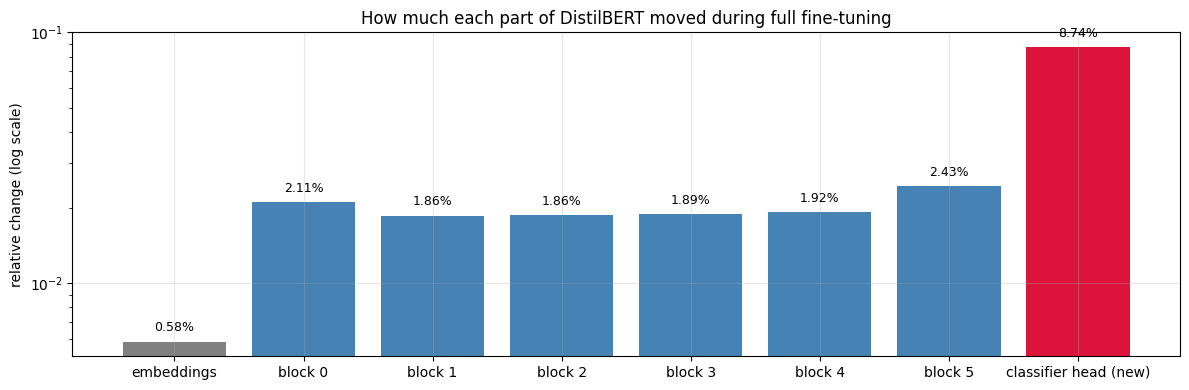

In [ ]:
def weight_change_by_group(model, init_state):
    num, den = collections.defaultdict(float), collections.defaultdict(float)
    for name, p in model.named_parameters():
        key = name if name in init_state else None
        if key is None: continue
        w0, w1 = init_state[key].float(), p.detach().float().cpu()
        m = re.search(r"layer\.(\d+)\.", name)
        g = f"block {m.group(1)}" if m else ("embeddings" if "embeddings" in name else "classifier head (new)")
        num[g] += (w1 - w0).pow(2).sum().item(); den[g] += w0.pow(2).sum().item()
    return {g: math.sqrt(num[g] / den[g]) for g in num}

changes = weight_change_by_group(full_model, init_state)
order = ["embeddings"] + [f"block {i}" for i in range(6)] + ["classifier head (new)"]
vals = [changes[g] for g in order if g in changes]
plt.figure(figsize=(12, 4))
bars = plt.bar([g for g in order if g in changes], vals, color=["gray"] + ["steelblue"] * 6 + ["crimson"])
plt.yscale("log"); plt.ylabel("relative change (log scale)")
plt.title("How much each part of DistilBERT moved during full fine-tuning")
for b_, v in zip(bars, vals):
    plt.text(b_.get_x() + b_.get_width() / 2, v * 1.1, f"{v:.2%}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

## Part 3 — LoRA: Low-Rank Adaptation
Full fine-tuning stores a *complete new copy* of the model per task and needs optimizer memory for every weight. For a 7B-parameter LLM that's ~100 GB of training state. LoRA's idea:

> Freeze the pre-trained weight **W** (d × k). Learn the *change* as a product of two skinny matrices:
> **W' = W + (α / r) · B · A**, with **B** (d × r) and **A** (r × k), and rank **r ≪ d**.

- **B starts at zero**, so on step 0 the model is *exactly* the pre-trained model (we'll exploit this in Part 5).
- Only A and B are trained → far fewer trainable parameters, less memory, tiny saved files (MBs instead of GBs).
- After training you can **merge** B·A into W, so inference costs nothing extra.

The bet is that the update ΔW needed for a new task is approximately **low-rank** — consistent with Part 2, where we saw the updates were small.

```
            frozen                      trainable
 x ──► [ W  (768×768) ] ──┐
   └──► [ A (r×768) ] ──► [ B (768×r) ] ──► × α/r ──┴──► (+) ──► output
```

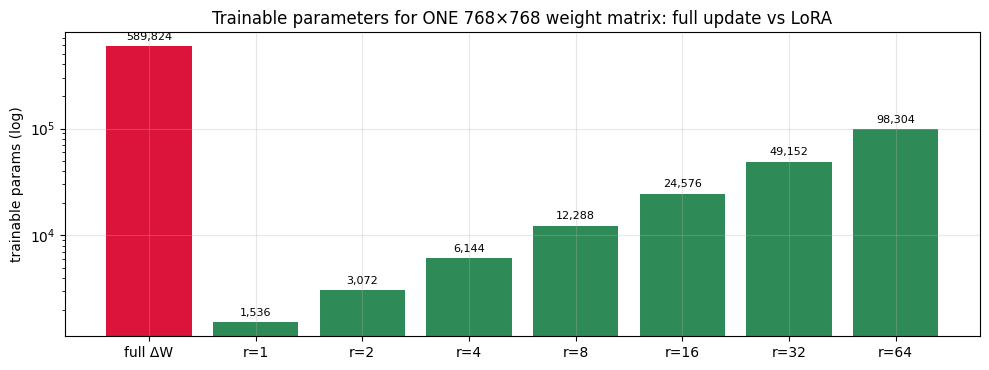

In [ ]:
d, ranks = 768, [1, 2, 4, 8, 16, 32, 64]
plt.figure(figsize=(10, 3.8))
plt.bar(["full ΔW"] + [f"r={r}" for r in ranks], [d * d] + [2 * d * r for r in ranks],
        color=["crimson"] + ["seagreen"] * len(ranks))
plt.yscale("log"); plt.ylabel("trainable params (log)")
plt.title("Trainable parameters for ONE 768×768 weight matrix: full update vs LoRA")
for i, v in enumerate([d * d] + [2 * d * r for r in ranks]):
    plt.text(i, v * 1.15, f"{v:,}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Fix: Colab's preinstalled torchao (0.10) is too old for the current PEFT. We don't need it, so remove it.
!pip uninstall -y -q torchao

def make_lora_cls_model(r=8, alpha=16, dropout=0.1,
                        targets=("q_lin", "k_lin", "v_lin", "out_lin", "lin1", "lin2")):
    base = make_cls_model()
    cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=r, lora_alpha=alpha, lora_dropout=dropout,
                     target_modules=list(targets),
                     modules_to_save=["pre_classifier", "classifier"])   # the new head must be trained fully
    return get_peft_model(base, cfg)

lora_model = make_lora_cls_model(r=8, alpha=16)
lora_model.print_trainable_parameters()
tr_l, tot_l = count_params(lora_model)

# Peek inside: one adapted layer
for n, m in lora_model.named_modules():
    if n.endswith("layer.0.attention.q_lin"):
        print("\n", n, "→", type(m).__name__)
        print("  frozen W :", tuple(m.base_layer.weight.shape), "requires_grad =", m.base_layer.weight.requires_grad)
        print("  LoRA A   :", tuple(m.lora_A['default'].weight.shape))
        print("  LoRA B   :", tuple(m.lora_B['default'].weight.shape), "| all zeros at init:", bool((m.lora_B['default'].weight == 0).all()))
        break

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

trainable params: 1,258,758 || all params: 68,216,844 || trainable%: 1.8452

 base_model.model.distilbert.transformer.layer.0.attention.q_lin → Linear
  frozen W : (768, 768) requires_grad = False
  LoRA A   : (8, 768)
  LoRA B   : (768, 8) | all zeros at init: True


LoRA tolerates (and usually needs) a **higher learning rate** than full fine-tuning (5e-4 vs 5e-5), because B·A starts at zero and only a few parameters move. Same data, same epochs:

[LoRA r=8] ep 1 step   50/500 | train loss 1.4905 | val loss 1.0297 | val acc 0.655
[LoRA r=8] ep 1 step  100/500 | train loss 0.7023 | val loss 0.4894 | val acc 0.836
[LoRA r=8] ep 1 step  150/500 | train loss 0.4115 | val loss 0.3302 | val acc 0.894
[LoRA r=8] ep 1 step  200/500 | train loss 0.3204 | val loss 0.2561 | val acc 0.903
[LoRA r=8] ep 1 step  250/500 | train loss 0.2632 | val loss 0.1990 | val acc 0.923
[LoRA r=8] ep 2 step  300/500 | train loss 0.1976 | val loss 0.1914 | val acc 0.915
[LoRA r=8] ep 2 step  350/500 | train loss 0.1753 | val loss 0.1883 | val acc 0.925
[LoRA r=8] ep 2 step  400/500 | train loss 0.1786 | val loss 0.1766 | val acc 0.934
[LoRA r=8] ep 2 step  450/500 | train loss 0.1843 | val loss 0.1615 | val acc 0.933
[LoRA r=8] ep 2 step  500/500 | train loss 0.1753 | val loss 0.1536 | val acc 0.938

TEST accuracy 0.918 | macro-F1 0.874


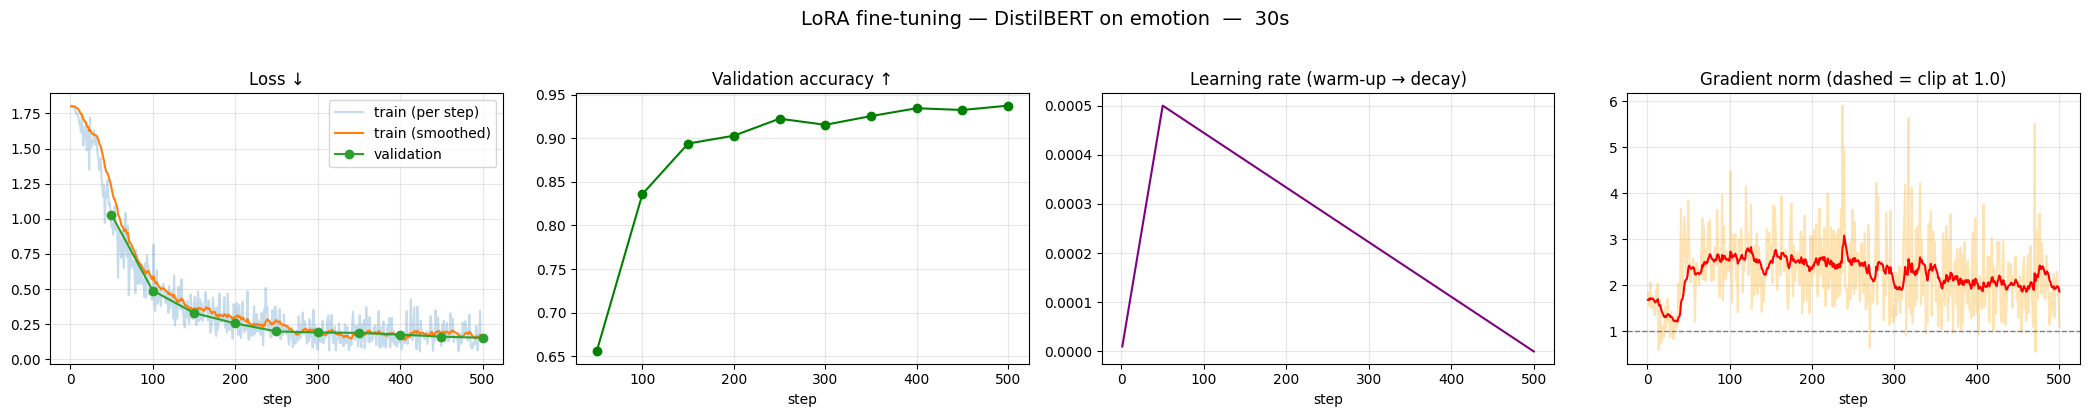

⏱  4.3 min since the notebook started


In [ ]:
torch.cuda.reset_peak_memory_stats()
hist_lora = train(lora_model, train_loader, lambda m: evaluate_cls(m, val_loader),
                  epochs=2, lr=5e-4, eval_every=50, desc="LoRA r=8")
test_lora = evaluate_cls(lora_model, test_loader)
RESULTS["LoRA (r=8)"] = dict(trainable=tr_l, total=tot_l, time_s=hist_lora["time"],
                             peak_mem_gb=torch.cuda.max_memory_allocated() / 1e9,
                             test_acc=test_lora["acc"], test_f1=test_lora["f1"])
print(f"\nTEST accuracy {test_lora['acc']:.3f} | macro-F1 {test_lora['f1']:.3f}")
plot_history(hist_lora, "LoRA fine-tuning — DistilBERT on emotion")
elapsed()

### Full fine-tuning vs LoRA, side by side
On a small 66M model the memory/time savings are modest (the activations dominate). On billion-parameter LLMs they are the difference between "needs 8 GPUs" and "fits on one".

,trainable,total,time_s,peak_mem_gb,test_acc,test_f1
Full fine-tune,"66,958,086","66,958,086",20.7,1.81,0.928,0.881
LoRA (r=8),"1,258,758","68,216,844",30.0,2.07,0.918,0.874


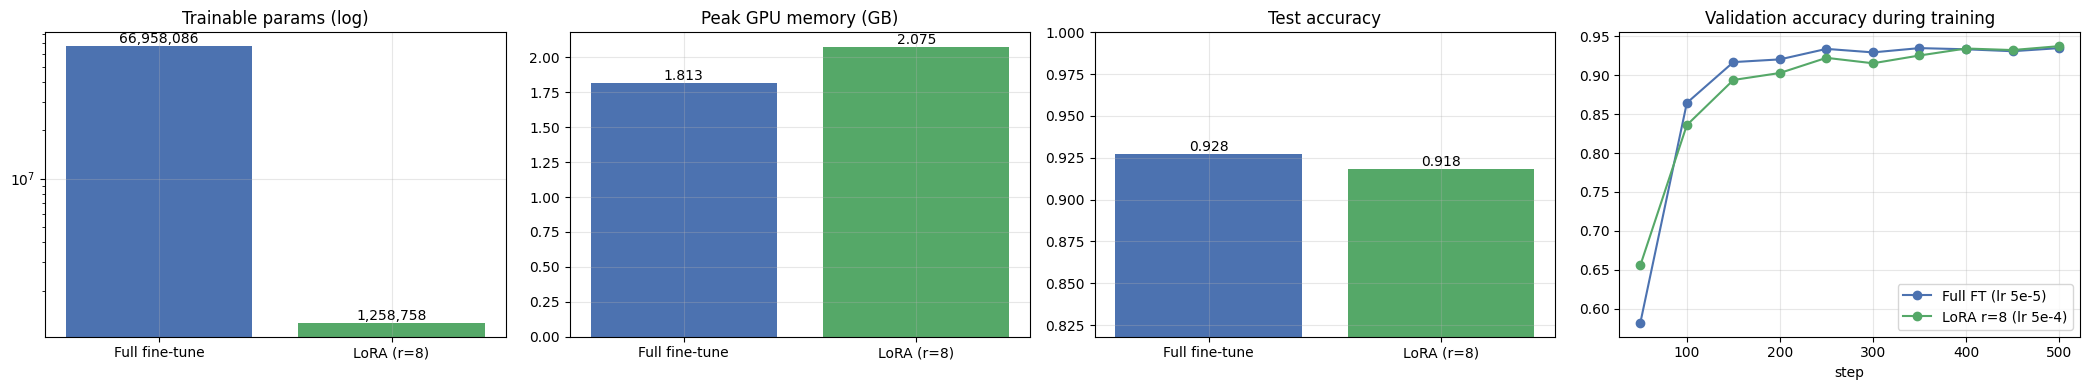

In [ ]:
df_res = pd.DataFrame(RESULTS).T
display(df_res.style.format({"trainable": "{:,.0f}", "total": "{:,.0f}", "time_s": "{:.1f}",
                             "peak_mem_gb": "{:.2f}", "test_acc": "{:.3f}", "test_f1": "{:.3f}"}))

fig, ax = plt.subplots(1, 4, figsize=(21, 4))
cols = ["#4C72B0", "#55A868"]
for a, (col, ttl, log) in zip(ax[:3], [("trainable", "Trainable params (log)", True),
                                         ("peak_mem_gb", "Peak GPU memory (GB)", False),
                                         ("test_acc", "Test accuracy", False)]):
    a.bar(df_res.index, df_res[col].astype(float), color=cols); a.set_title(ttl)
    if log: a.set_yscale("log")
    for i, v in enumerate(df_res[col].astype(float)):
        a.text(i, v, f"{v:,.0f}" if col == "trainable" else f"{v:.3f}", ha="center", va="bottom")
ax[2].set_ylim(min(df_res.test_acc) - 0.1, 1.0)
ax[3].plot(hist_full["eval_step"], hist_full["val_acc"], "o-", label="Full FT (lr 5e-5)", color=cols[0])
ax[3].plot(hist_lora["eval_step"], hist_lora["val_acc"], "o-", label="LoRA r=8 (lr 5e-4)", color=cols[1])
ax[3].set_title("Validation accuracy during training"); ax[3].set_xlabel("step"); ax[3].legend()
plt.tight_layout(); plt.show()

### Is the update really low-rank?
Take the same matrix (block 5, query projection) and look at its update ΔW under both methods:

- **Heatmaps** of a 64×64 corner: the LoRA update has visible row/column structure (it's a rank-8 matrix by construction).
- **Singular-value energy:** how much of ΔW's "size" is captured by its top-k directions. A random matrix spreads energy evenly (a straight-ish line). The **full fine-tuning** update is far more concentrated than random — a few directions carry much of the change. That's the empirical justification for LoRA. LoRA's own update hits 100% at exactly k = r.

Rank of LoRA ΔW: 8 | rank of full-FT ΔW: 758


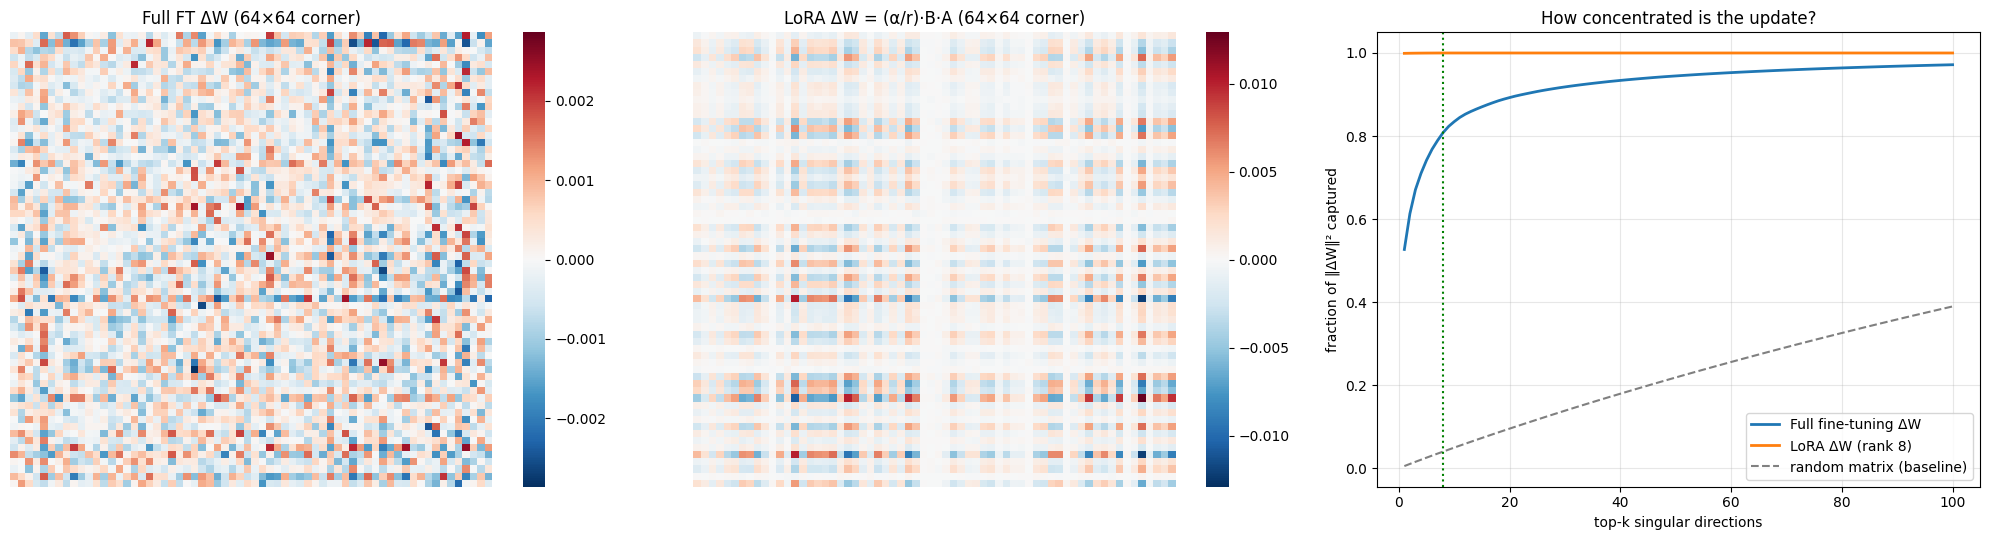

In [ ]:
LAYER = "transformer.layer.5.attention.q_lin"
for n, m in lora_model.named_modules():
    if n.endswith(LAYER) and hasattr(m, "lora_A"):
        A = m.lora_A["default"].weight.detach().float().cpu()
        B = m.lora_B["default"].weight.detach().float().cpu()
        delta_lora = (B @ A) * m.scaling["default"]
        break
key = f"distilbert.{LAYER}.weight"
delta_full = full_model.state_dict()[key].detach().float().cpu() - init_state[key].float()
rand = torch.randn_like(delta_full)

def energy(M, k=100):
    s = torch.linalg.svdvals(M)
    return (torch.cumsum(s ** 2, 0) / (s ** 2).sum())[:k].numpy()

print("Rank of LoRA ΔW:", torch.linalg.matrix_rank(delta_lora).item(), "| rank of full-FT ΔW:", torch.linalg.matrix_rank(delta_full).item())
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
for a, M, t in [(ax[0], delta_full, "Full FT ΔW (64×64 corner)"), (ax[1], delta_lora, "LoRA ΔW = (α/r)·B·A (64×64 corner)")]:
    v = M[:64, :64].abs().max().item()
    sns.heatmap(M[:64, :64].numpy(), cmap="RdBu_r", center=0, vmin=-v, vmax=v, ax=a, xticklabels=False, yticklabels=False)
    a.set_title(t)
k = np.arange(1, 101)
ax[2].plot(k, energy(delta_full), label="Full fine-tuning ΔW", lw=2)
ax[2].plot(k, energy(delta_lora), label="LoRA ΔW (rank 8)", lw=2)
ax[2].plot(k, energy(rand), "--", label="random matrix (baseline)", c="gray")
ax[2].axvline(8, ls=":", c="green"); ax[2].set_xlabel("top-k singular directions"); ax[2].set_ylabel("fraction of ‖ΔW‖² captured")
ax[2].set_title("How concentrated is the update?"); ax[2].legend()
plt.tight_layout(); plt.show()

In [ ]:
free_gpu("full_model", "lora_model")
elapsed()

⏱  4.6 min since the notebook started


## Part 4 — Hyperparameter lab
Short, cheap runs (4,000 training tweets, 1 epoch, ~5–10 s each) to build intuition for the knobs that matter most.

### 4a. Learning rate — the single most important knob
- Too **low** → the loss barely moves; you waste compute.
- Too **high** → the loss is noisy or explodes, and you destroy what pre-training learned.
- The sweet spot for LoRA is usually ~1e-4 to 1e-3.

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

lr=1e-05 → val acc 0.377 | final train loss 1.669 | 6.0s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

lr=1e-04 → val acc 0.539 | final train loss 1.226 | 6.2s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

lr=5e-04 → val acc 0.766 | final train loss 0.740 | 5.8s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

lr=2e-03 → val acc 0.882 | final train loss 0.445 | 5.9s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

lr=1e-02 → val acc 0.367 | final train loss 1.571 | 5.9s


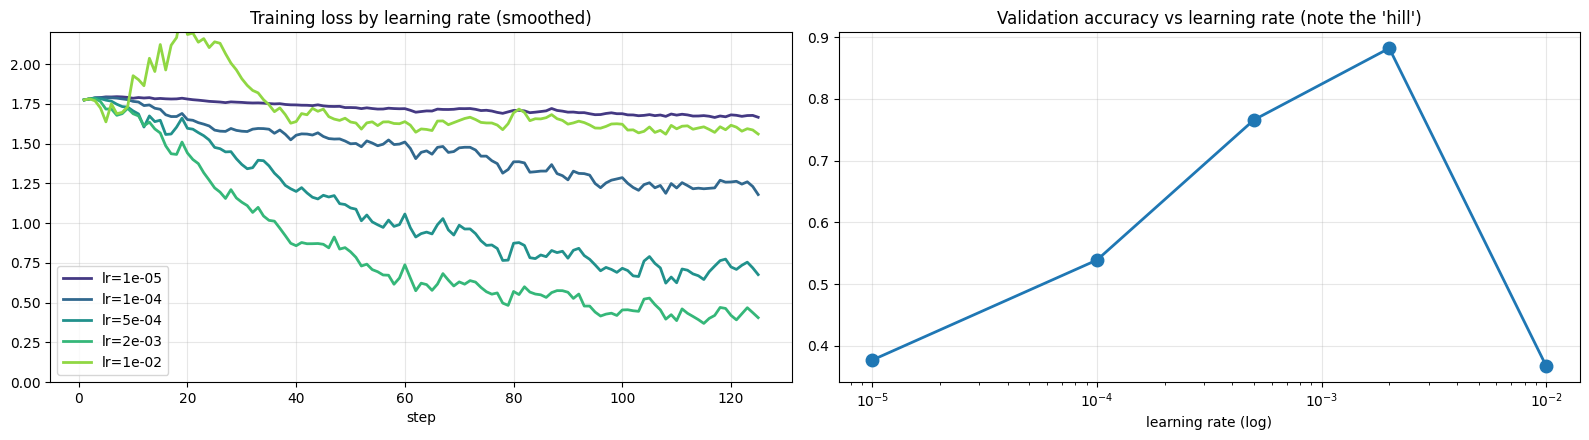

In [ ]:
sweep_train = make_loader("train", 32, shuffle=True, n=4000)
LRS = [1e-5, 1e-4, 5e-4, 2e-3, 1e-2]
sweep_lr = {}
for lr in LRS:
    m = make_lora_cls_model(r=8, alpha=16)
    h = train(m, sweep_train, lambda mm: evaluate_cls(mm, val_small), epochs=1, lr=lr,
              eval_every=10**9, verbose=False)
    sweep_lr[lr] = h
    print(f"lr={lr:.0e} → val acc {h['val_acc'][-1]:.3f} | final train loss {np.nanmean(h['loss'][-10:]):.3f} | {h['time']:.1f}s")
    del m; gc.collect(); torch.cuda.empty_cache()

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
pal = sns.color_palette("viridis", len(LRS))
for c, (lr, h) in zip(pal, sweep_lr.items()):
    ax[0].plot(h["step"], ema(h["loss"], 0.8), label=f"lr={lr:.0e}", color=c, lw=2)
ax[0].set_title("Training loss by learning rate (smoothed)"); ax[0].set_xlabel("step"); ax[0].legend(); ax[0].set_ylim(0, 2.2)
ax[1].semilogx(LRS, [sweep_lr[lr]["val_acc"][-1] for lr in LRS], "o-", lw=2, ms=9)
ax[1].set_title("Validation accuracy vs learning rate (note the 'hill')"); ax[1].set_xlabel("learning rate (log)")
plt.tight_layout(); plt.show()

### 4b. LoRA rank r
Higher rank = more capacity, more parameters. Accuracy usually **saturates quickly** — for many tasks r = 4–16 is enough. We keep α = 2r so the effective update scale stays comparable.

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

r=  1 → val acc 0.669 | trainable 678,150


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

r=  4 → val acc 0.721 | trainable 926,982


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

r= 16 → val acc 0.794 | trainable 1,922,310


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

r= 64 → val acc 0.883 | trainable 5,903,622


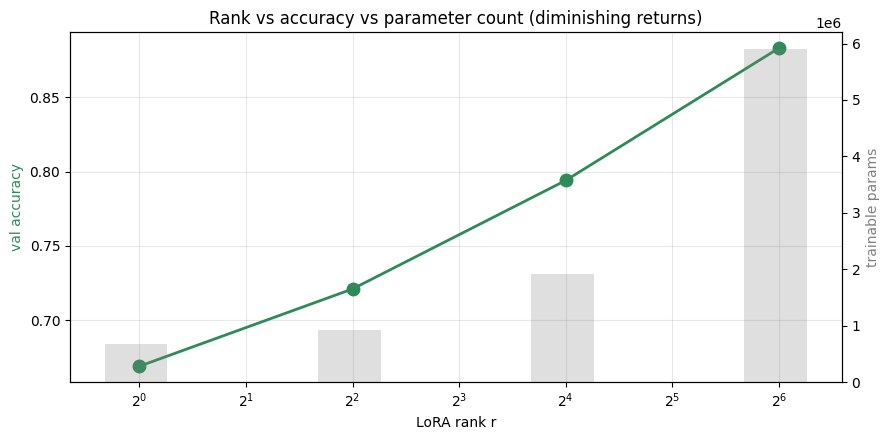

In [ ]:
RANKS = [1, 4, 16, 64]
sweep_r = {}
for r in RANKS:
    m = make_lora_cls_model(r=r, alpha=2 * r)
    trn, _ = count_params(m)
    h = train(m, sweep_train, lambda mm: evaluate_cls(mm, val_small), epochs=1, lr=5e-4,
              eval_every=10**9, verbose=False)
    sweep_r[r] = (h["val_acc"][-1], trn)
    print(f"r={r:3d} → val acc {h['val_acc'][-1]:.3f} | trainable {trn:,}")
    del m; gc.collect(); torch.cuda.empty_cache()

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(RANKS, [sweep_r[r][0] for r in RANKS], "o-", c="seagreen", lw=2, ms=9, label="val accuracy")
ax1.set_xscale("log", base=2); ax1.set_xlabel("LoRA rank r"); ax1.set_ylabel("val accuracy", color="seagreen")
ax2 = ax1.twinx(); ax2.bar(RANKS, [sweep_r[r][1] for r in RANKS], width=[r * 0.4 for r in RANKS], alpha=0.25, color="gray")
ax2.set_ylabel("trainable params", color="gray"); ax2.grid(False)
plt.title("Rank vs accuracy vs parameter count (diminishing returns)"); plt.tight_layout(); plt.show()

### 4c. Overfitting — the classic failure mode
Fine-tune on only **200** examples for **25 epochs**. Training loss heads to zero (the model memorises), but validation loss goes **down, then up**. The point where validation loss is lowest is where you should have stopped — that's **early stopping**. Remedies: more data, fewer epochs, lower LR, weight decay/dropout, or LoRA (fewer parameters to overfit with).

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

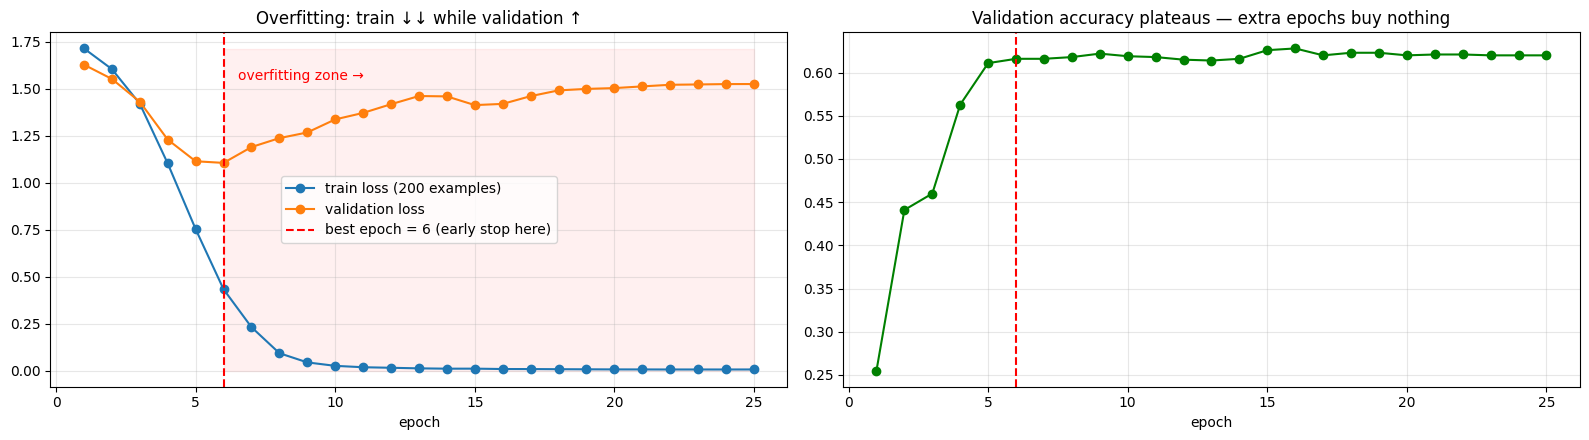

⏱  6.1 min since the notebook started


In [ ]:
tiny_loader = make_loader("train", 16, shuffle=True, n=200)
spe, EPOCHS_OF = len(tiny_loader), 25
of_model = make_cls_model()
hist_of = train(of_model, tiny_loader, lambda mm: evaluate_cls(mm, val_small), epochs=EPOCHS_OF, lr=5e-5,
                warmup_ratio=0.0, eval_every=spe, verbose=False)
del of_model; gc.collect(); torch.cuda.empty_cache()

ep_train = [np.mean(hist_of["loss"][i * spe:(i + 1) * spe]) for i in range(EPOCHS_OF)]
ep = np.arange(1, EPOCHS_OF + 1)
best = int(np.argmin(hist_of["val_loss"]))
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].plot(ep, ep_train, "o-", label="train loss (200 examples)")
ax[0].plot(ep, hist_of["val_loss"], "o-", label="validation loss")
ax[0].axvline(ep[best], ls="--", c="red", label=f"best epoch = {ep[best]} (early stop here)")
ax[0].fill_between(ep[best:], 0, max(hist_of["val_loss"]) * 1.05, color="red", alpha=0.06)
ax[0].text(ep[best] + 0.5, max(hist_of["val_loss"]) * 0.95, "overfitting zone →", color="red")
ax[0].set_title("Overfitting: train ↓↓ while validation ↑"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep, hist_of["val_acc"], "o-", c="green"); ax[1].axvline(ep[best], ls="--", c="red")
ax[1].set_title("Validation accuracy plateaus — extra epochs buy nothing"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()
elapsed()

## Part 5 — Fine-tuning a Large Language Model (instruction tuning / SFT)
Now the fun part: teach a chat LLM (**Qwen2.5-0.5B-Instruct**, no login needed) a new, precise skill — turning messy coffee orders into JSON with **our exact schema**:

```
"hey can i grab 2 big mochas with oat milk"  →  {"item": "mocha", "size": "large", "quantity": 2, "milk": "oat"}
```

The model has to learn: our key names, normalising synonyms (*big / grande → large*, *regular → medium*), number words → integers, singularising (*mochas → mocha*), and `"none"` when no milk is mentioned.

**Key LLM fine-tuning ideas you'll see:**
1. **Supervised fine-tuning (SFT):** train on (prompt → ideal answer) pairs with the same next-token loss as pre-training.
2. **Chat template:** format examples exactly the way the model saw chats during its own training.
3. **Loss masking:** only the *answer* tokens contribute to the loss — we don't train the model to predict our prompt.

In [ ]:
random.seed(SEED)
ITEMS = ["latte", "cappuccino", "espresso", "mocha", "americano", "flat white",
         "chai latte", "hot chocolate", "matcha latte", "cold brew"]
SIZE_WORDS = {"small": ["small", "short", "little"], "medium": ["medium", "regular"], "large": ["large", "big", "grande"]}
MILKS = ["whole", "skim", "oat", "almond", "soy", "none"]
QTY_WORDS = {1: ["one", "1", "a single"], 2: ["two", "2"], 3: ["three", "3"], 4: ["four", "4"]}
TEMPLATES = [
    "Can I get {qty} {size} {item}{milk}?",
    "I'd like {qty} {item}{milk}, {size} please.",
    "{qty} {size} {item}{milk} for me, thanks.",
    "Could you make me {qty} {size} {item}{milk}?",
    "hey can i grab {qty} {size} {item}{milk}",
    "Order: {qty} {item} ({size}){milk}.",
    "yo {qty} {size} {item}{milk} pls",
]

def milk_phrase(m):
    if m == "none":
        return random.choice(["", "", " with no milk", ", no milk"])
    return random.choice([f" with {m} milk", f", {m} milk", f" made with {m} milk"])

def make_order():
    item, size, n, milk = random.choice(ITEMS), random.choice(list(SIZE_WORDS)), random.randint(1, 4), random.choice(MILKS)
    text = random.choice(TEMPLATES).format(qty=random.choice(QTY_WORDS[n]), size=random.choice(SIZE_WORDS[size]),
                                           item=item if n == 1 else item + "s", milk=milk_phrase(milk))
    return text, json.dumps({"item": item, "size": size, "quantity": n, "milk": milk})

seen, data = set(), []
while len(data) < 2400:
    t, y = make_order()
    if t not in seen:
        seen.add(t); data.append((t, y))
random.shuffle(data)
train_pairs, val_pairs, test_pairs = data[:2000], data[2000:2200], data[2200:2400]
print(f"train {len(train_pairs)} | val {len(val_pairs)} | test {len(test_pairs)}\n")
for t, y in train_pairs[:6]:
    print(f"{t:55s} →  {y}")

train 2000 | val 200 | test 200

I'd like two chai lattes, oat milk, short please.       →  {"item": "chai latte", "size": "small", "quantity": 2, "milk": "oat"}
Order: four lattes (medium) with almond milk.           →  {"item": "latte", "size": "medium", "quantity": 4, "milk": "almond"}
Can I get three short cold brews made with soy milk?    →  {"item": "cold brew", "size": "small", "quantity": 3, "milk": "soy"}
I'd like 2 americanos, whole milk, small please.        →  {"item": "americano", "size": "small", "quantity": 2, "milk": "whole"}
I'd like three cold brews with whole milk, big please.  →  {"item": "cold brew", "size": "large", "quantity": 3, "milk": "whole"}
I'd like 2 lattes, grande please.                       →  {"item": "latte", "size": "large", "quantity": 2, "milk": "none"}


In [ ]:
LLM_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
llm_tok = AutoTokenizer.from_pretrained(LLM_NAME)
if llm_tok.pad_token is None:
    llm_tok.pad_token = llm_tok.eos_token
llm_tok.padding_side = "right"
END = llm_tok.eos_token          # '<|im_end|>' for Qwen instruct models: "assistant turn is over"

SYSTEM = "You are a helpful assistant."
INSTRUCTION = "Convert this coffee order to JSON:\n"
FEW_SHOT = ("Reply with ONLY a JSON object with keys item, size (small/medium/large), "
            "quantity (integer), milk (whole/skim/oat/almond/soy/none).\nExamples:\n"
            + "\n".join(f"Order: {t}\nJSON: {y}" for t, y in train_pairs[:3]) + "\n\n")

def build_prompt(text, few_shot=False, raw=False):
    user = text if raw else (FEW_SHOT if few_shot else "") + INSTRUCTION + text
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user}]
    return llm_tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def encode_example(text, target):
    p_ids = llm_tok(build_prompt(text), add_special_tokens=False)["input_ids"]
    a_ids = llm_tok(target + END, add_special_tokens=False)["input_ids"]
    return {"input_ids": p_ids + a_ids, "labels": [-100] * len(p_ids) + a_ids}   # -100 = ignored by the loss

print("What the model actually sees (chat template applied):\n")
print(build_prompt(train_pairs[0][0]) + train_pairs[0][1] + END)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

What the model actually sees (chat template applied):

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Convert this coffee order to JSON:
I'd like two chai lattes, oat milk, short please.<|im_end|>
<|im_start|>assistant
{"item": "chai latte", "size": "small", "quantity": 2, "milk": "oat"}<|im_end|>


### Loss masking, visualised
Each box is one token. **Gray** tokens are the prompt — their label is `-100`, so they contribute nothing to the loss. **Green** tokens are the answer — the only thing the model is trained to produce. (Also notice how the tokenizer splits words and JSON punctuation.)

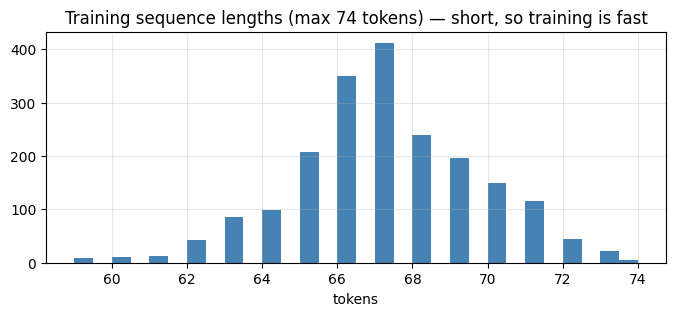

In [ ]:
def show_loss_mask(ex):
    spans = []
    for tid, lab in zip(ex["input_ids"], ex["labels"]):
        t = html.escape(llm_tok.decode([tid])).replace("\n", "↵")
        bg = "#b7f0b1" if lab != -100 else "#e6e6e6"
        spans.append(f'<span style="background:{bg};color:#111;padding:2px 3px;margin:1px;'
                     f'border-radius:4px;font-family:monospace;font-size:12px;display:inline-block">{t}</span>')
    n_ans = sum(l != -100 for l in ex["labels"])
    display(HTML(f"<div style='line-height:2.1'>{''.join(spans)}</div>"
                 f"<p><b>{len(ex['input_ids'])}</b> tokens total → only <b>{n_ans}</b> (green) are trained on.</p>"))

train_enc = [encode_example(t, y) for t, y in train_pairs]
val_enc = [encode_example(t, y) for t, y in val_pairs]
show_loss_mask(train_enc[0])

lens = [len(e["input_ids"]) for e in train_enc]
plt.figure(figsize=(8, 3)); plt.hist(lens, bins=30, color="steelblue")
plt.title(f"Training sequence lengths (max {max(lens)} tokens) — short, so training is fast"); plt.xlabel("tokens"); plt.show()

### Load the LLM and attach LoRA adapters
We adapt **every linear layer** in attention (q, k, v, o) and the MLP (gate, up, down) — the standard recipe for LLMs. Then we measure the model *before training*.

Remember: LoRA's **B starts at zero**, so the wrapped model is *mathematically identical* to the original right now — our "before" numbers are the true baseline. We'll compare two ways of using the un-tuned model:
- **zero-shot:** just the short instruction
- **few-shot prompting:** schema described + 3 examples in the prompt (the "no training" alternative to fine-tuning)

In [ ]:
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME).float().to(device)
for k_ in ("temperature", "top_p", "top_k"):
    setattr(llm.generation_config, k_, None)   # we decode greedily

lora_cfg = LoraConfig(task_type=TaskType.CAUSAL_LM, r=16, lora_alpha=32, lora_dropout=0.05,
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
llm = get_peft_model(llm, lora_cfg)
llm.print_trainable_parameters()

@torch.no_grad()
def generate(model, prompts, max_new_tokens=64, bs=50):
    model.eval(); llm_tok.padding_side = "left"   # left-pad for batched generation
    outs = []
    for i in range(0, len(prompts), bs):
        enc = llm_tok(prompts[i:i + bs], return_tensors="pt", padding=True, add_special_tokens=False).to(device)
        with autocast():
            g = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=llm_tok.pad_token_id)
        outs += llm_tok.batch_decode(g[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    llm_tok.padding_side = "right"
    return outs

FIELDS = ["item", "size", "quantity", "milk"]
def parse_json(s):
    m = re.search(r"\{.*?\}", s, re.S)
    if not m: return None
    try:
        d_ = json.loads(m.group(0)); return d_ if isinstance(d_, dict) else None
    except Exception:
        return None

def score(outputs, pairs):
    res = {"valid JSON": 0, **{f: 0 for f in FIELDS}, "exact match": 0}
    for o, (_, y) in zip(outputs, pairs):
        gold, pred = json.loads(y), parse_json(o)
        if pred is None: continue
        res["valid JSON"] += 1
        ok = True
        for f in FIELDS:
            if str(pred.get(f)).strip().lower() == str(gold[f]).lower(): res[f] += 1
            else: ok = False
        res["exact match"] += ok
    return {k: v / len(pairs) for k, v in res.items()}

t0 = time.time()
out_zero = generate(llm, [build_prompt(t) for t, _ in test_pairs])
out_few = generate(llm, [build_prompt(t, few_shot=True) for t, _ in test_pairs])
scores = {"zero-shot (no training)": score(out_zero, test_pairs), "few-shot prompt (no training)": score(out_few, test_pairs)}
print(f"Generated {2 * len(test_pairs)} answers in {time.time() - t0:.0f}s\n")
display(pd.DataFrame(scores).T.style.format("{:.0%}"))
for i in range(3):
    print(f"\nORDER : {test_pairs[i][0]}\nGOLD  : {test_pairs[i][1]}\nZERO  : {out_zero[i].strip()[:150]}\nFEW   : {out_few[i].strip()[:150]}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
Generated 400 answers in 28s



,valid JSON,item,size,quantity,milk,exact match
zero-shot (no training),0%,0%,0%,0%,0%,0%
few-shot prompt (no training),100%,83%,75%,100%,98%,63%



ORDER : Can I get 3 regular mochas with almond milk?
GOLD  : {"item": "mocha", "size": "medium", "quantity": 3, "milk": "almond"}
ZERO  : ```json
{
  "order": {
    "coffee_type": "regular_mocha",
    "quantity": 3,
    "almond_milk": true
  }
}
```
FEW   : {"item": "mocha", "size": "large", "quantity": 3, "milk": "almond"}

ORDER : hey can i grab three little mochas with whole milk
GOLD  : {"item": "mocha", "size": "small", "quantity": 3, "milk": "whole"}
ZERO  : ```json
{
  "order": {
    "customer_name": "John Doe",
    "order_date": "",
    "order_time": "",
    "coffee_order": [
      {
        "coffee_type
FEW   : {"item": "mocha", "size": "small", "quantity": 3, "milk": "whole"}

ORDER : I'd like 3 chai lattes with skim milk, medium please.
GOLD  : {"item": "chai latte", "size": "medium", "quantity": 3, "milk": "skim"}
ZERO  : ```json
{
  "order": {
    "coffee_type": "chai",
    "quantity": 3,
    "drinks": [
      {
        "name": "Chai Latte",
        "quantity": 1,
    
FE

### Train
Typical LLM-LoRA recipe: **lr 2e-4, cosine schedule, short warm-up, 2 epochs**. The validation panel shows **perplexity** (e^loss): "how many tokens is the model hesitating between?" — it should fall towards 1, meaning the model is near-certain of the right answer.

[Qwen LoRA SFT] ep 1 step   25/250 | train loss 0.2861 | val loss 0.0050
[Qwen LoRA SFT] ep 1 step   50/250 | train loss 0.0811 | val loss 0.0004
[Qwen LoRA SFT] ep 1 step   75/250 | train loss 0.0016 | val loss 0.0003
[Qwen LoRA SFT] ep 1 step  100/250 | train loss 0.0003 | val loss 0.0001
[Qwen LoRA SFT] ep 1 step  125/250 | train loss 0.0001 | val loss 0.0000
[Qwen LoRA SFT] ep 2 step  150/250 | train loss 0.0000 | val loss 0.0000
[Qwen LoRA SFT] ep 2 step  175/250 | train loss 0.0000 | val loss 0.0000
[Qwen LoRA SFT] ep 2 step  200/250 | train loss 0.0000 | val loss 0.0000
[Qwen LoRA SFT] ep 2 step  225/250 | train loss 0.0000 | val loss 0.0000
[Qwen LoRA SFT] ep 2 step  250/250 | train loss 0.0000 | val loss 0.0000
Peak GPU memory: 11.2 GB


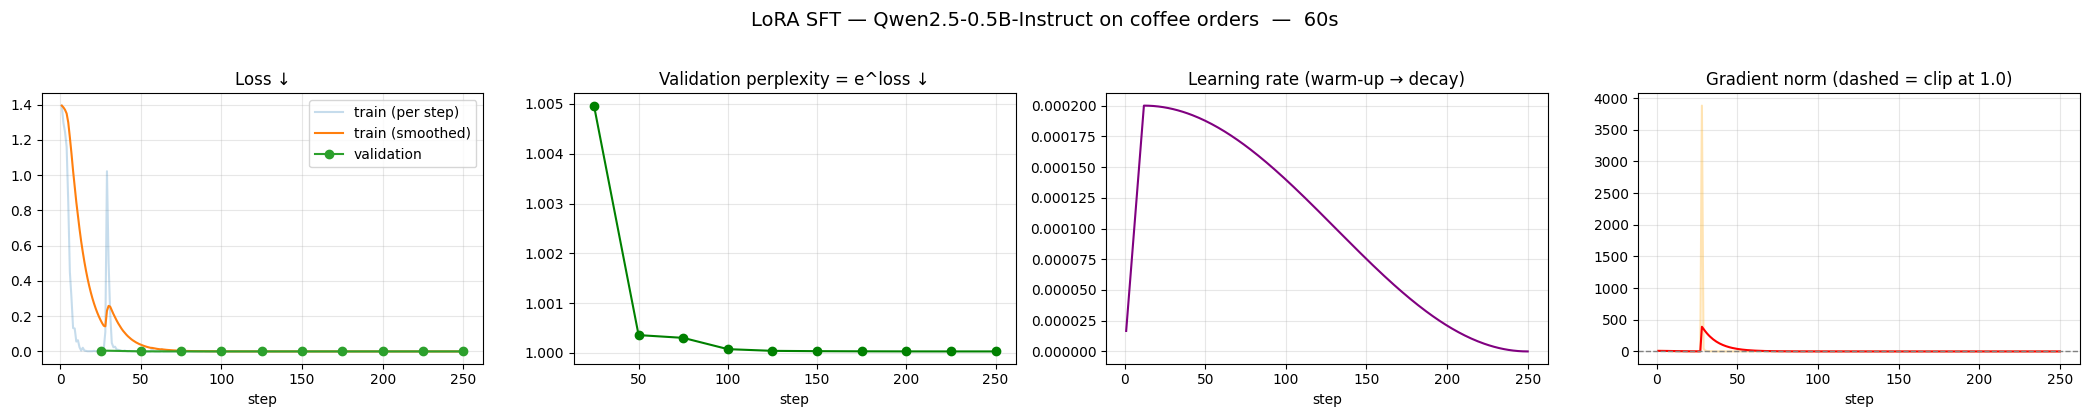

⏱  8.4 min since the notebook started


In [ ]:
def collate_lm(batch):
    L = max(len(x["input_ids"]) for x in batch)
    ids = torch.full((len(batch), L), llm_tok.pad_token_id)
    lab = torch.full((len(batch), L), -100)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    for i, x in enumerate(batch):
        n = len(x["input_ids"])
        ids[i, :n] = torch.tensor(x["input_ids"]); lab[i, :n] = torch.tensor(x["labels"]); att[i, :n] = 1
    return {"input_ids": ids, "attention_mask": att, "labels": lab}

lm_train_loader = DataLoader(train_enc, batch_size=16, shuffle=True, collate_fn=collate_lm)
lm_val_loader = DataLoader(val_enc, batch_size=64, collate_fn=collate_lm)

@torch.no_grad()
def eval_lm_loss(model, loader):
    model.eval(); tot, n = 0.0, 0
    for b in loader:
        b = {k: v.to(device) for k, v in b.items()}
        with autocast():
            out = model(**b)
        ntok = (b["labels"][:, 1:] != -100).sum().item()
        tot += out.loss.float().item() * ntok; n += ntok
    return {"loss": tot / n}

torch.cuda.reset_peak_memory_stats()
set_seed()
hist_lm = train(llm, lm_train_loader, lambda m: eval_lm_loss(m, lm_val_loader), epochs=2, lr=2e-4,
                weight_decay=0.0, warmup_ratio=0.05, schedule="cosine", eval_every=25, desc="Qwen LoRA SFT")
print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
plot_history(hist_lm, "LoRA SFT — Qwen2.5-0.5B-Instruct on coffee orders")
elapsed()

### Before vs after

,valid JSON,item,size,quantity,milk,exact match
zero-shot (no training),0%,0%,0%,0%,0%,0%
few-shot prompt (no training),100%,83%,75%,100%,98%,63%
fine-tuned (LoRA),100%,100%,100%,100%,100%,100%


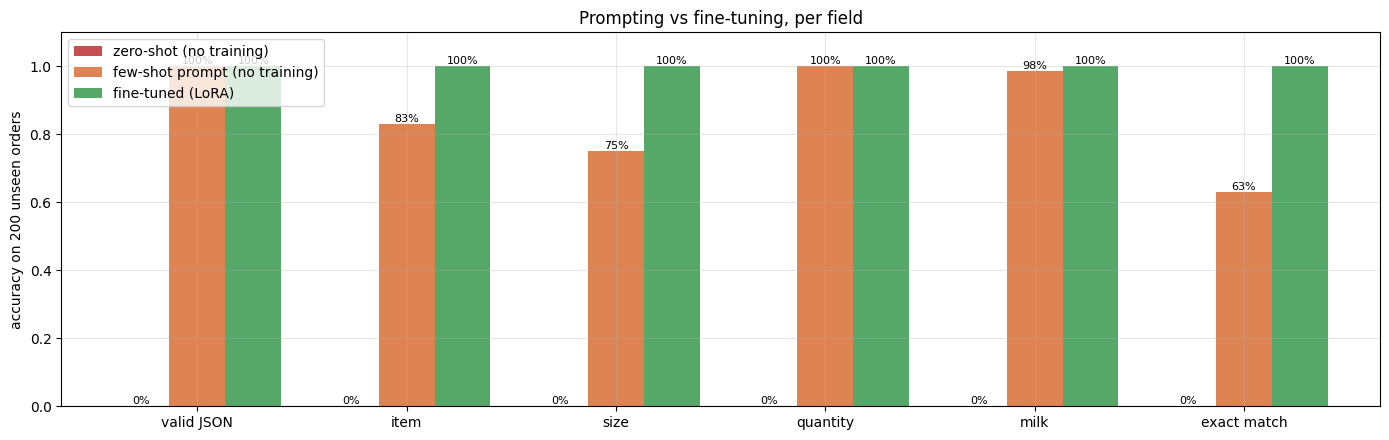

,order,gold,zero-shot,fine-tuned
0,Can I get 3 regular mochas with almond milk?,"{""item"": ""mocha"", ""size"": ""medium"", ""quantity"": 3, ""milk"": ""almond""}","```json\n{\n ""order"": {\n ""coffee_type"": ""regular_mocha"",\n ""quantity...","{""item"": ""mocha"", ""size"": ""medium"", ""quantity"": 3, ""milk"": ""almond""}"
1,hey can i grab three little mochas with whole milk,"{""item"": ""mocha"", ""size"": ""small"", ""quantity"": 3, ""milk"": ""whole""}","```json\n{\n ""order"": {\n ""customer_name"": ""John Doe"",\n ""order_date""...","{""item"": ""mocha"", ""size"": ""small"", ""quantity"": 3, ""milk"": ""whole""}"
2,"I'd like 3 chai lattes with skim milk, medium please.","{""item"": ""chai latte"", ""size"": ""medium"", ""quantity"": 3, ""milk"": ""skim""}","```json\n{\n ""order"": {\n ""coffee_type"": ""chai"",\n ""quantity"": 3,\n ...","{""item"": ""chai latte"", ""size"": ""medium"", ""quantity"": 3, ""milk"": ""skim""}"
3,"I'd like one cappuccino, soy milk, large please.","{""item"": ""cappuccino"", ""size"": ""large"", ""quantity"": 1, ""milk"": ""soy""}","{\n ""order"": {\n ""coffee"": {\n ""name"": ""cappuccino"",\n ""quanti...","{""item"": ""cappuccino"", ""size"": ""large"", ""quantity"": 1, ""milk"": ""soy""}"
4,"yo three grande hot chocolates, whole milk pls","{""item"": ""hot chocolate"", ""size"": ""large"", ""quantity"": 3, ""milk"": ""whole""}","```json\n{\n ""order"": {\n ""coffee"": [\n {\n ""type"": ""hot"",\n...","{""item"": ""hot chocolate"", ""size"": ""large"", ""quantity"": 3, ""milk"": ""whole""}"
5,hey can i grab three regular flat whites with soy milk,"{""item"": ""flat white"", ""size"": ""medium"", ""quantity"": 3, ""milk"": ""soy""}","```json\n{\n ""order"": {\n ""customer_name"": ""John Doe"",\n ""order_date""...","{""item"": ""flat white"", ""size"": ""medium"", ""quantity"": 3, ""milk"": ""soy""}"
6,"Order: three flat whites (medium), oat milk.","{""item"": ""flat white"", ""size"": ""medium"", ""quantity"": 3, ""milk"": ""oat""}","{\n ""order"": {\n ""coffee_type"": ""flat white"",\n ""quantity"": 3,\n ""...","{""item"": ""flat white"", ""size"": ""medium"", ""quantity"": 3, ""milk"": ""oat""}"
7,yo one small americano pls,"{""item"": ""americano"", ""size"": ""small"", ""quantity"": 1, ""milk"": ""none""}","```json\n{\n ""order"": {\n ""item"": ""small americano"",\n ""quantity"": 1,...","{""item"": ""americano"", ""size"": ""small"", ""quantity"": 1, ""milk"": ""none""}"


In [ ]:
out_ft = generate(llm, [build_prompt(t) for t, _ in test_pairs])
scores["fine-tuned (LoRA)"] = score(out_ft, test_pairs)
df_s = pd.DataFrame(scores).T
display(df_s.style.format("{:.0%}"))

ax = df_s.T.plot(kind="bar", figsize=(14, 4.5), color=["#C44E52", "#DD8452", "#55A868"], width=0.8)
ax.set_ylim(0, 1.1); ax.set_ylabel("accuracy on 200 unseen orders"); ax.set_title("Prompting vs fine-tuning, per field")
ax.legend(loc="upper left"); plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0%}" for v in c.datavalues], fontsize=8)
plt.tight_layout(); plt.show()

pd.set_option("display.max_colwidth", 80)
display(pd.DataFrame({"order": [t for t, _ in test_pairs[:8]], "gold": [y for _, y in test_pairs[:8]],
                      "zero-shot": [o.strip()[:80] for o in out_zero[:8]],
                      "fine-tuned": [o.strip() for o in out_ft[:8]]}))

### Where did the learning happen? Per-token loss
For one unseen example we measure the loss on **each answer token**, with the adapter switched **off** (original model) vs **on** (fine-tuned). High bars = "the model was surprised by this token". Before: the key names, the normalised values (`large`, `none`) and JSON structure are surprising. After: everything is near zero.

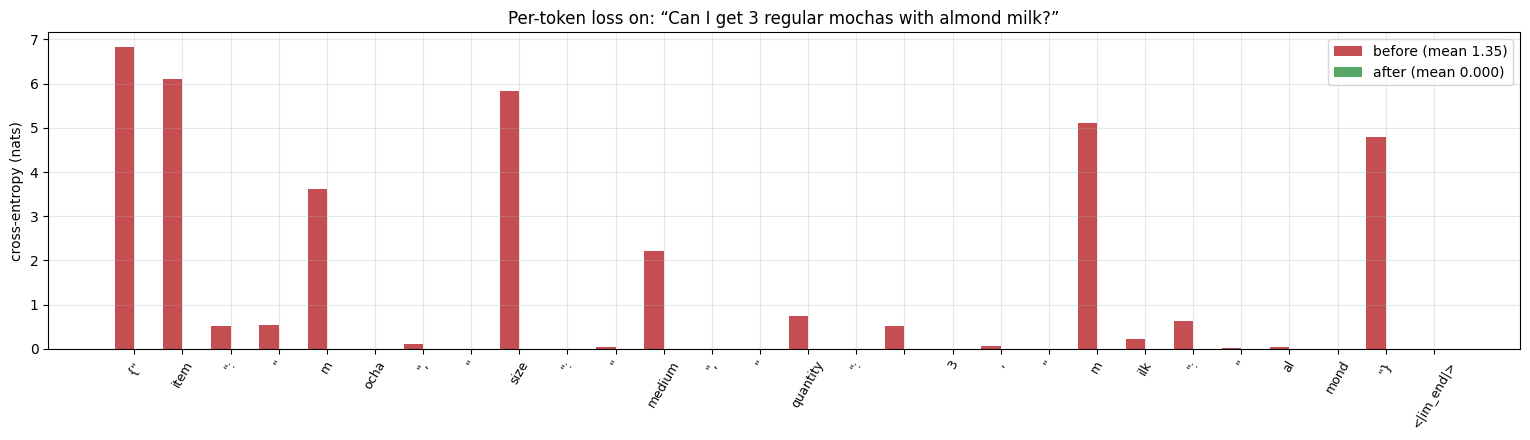

In [ ]:
@torch.no_grad()
def per_token_loss(model, ex):
    ids = torch.tensor([ex["input_ids"]], device=device); labels = torch.tensor([ex["labels"]], device=device)
    with autocast():
        logits = model(input_ids=ids).logits.float()
    l = F.cross_entropy(logits[0, :-1], labels[0, 1:], ignore_index=-100, reduction="none")
    mask = labels[0, 1:] != -100
    toks = [llm_tok.decode([t]).replace("\n", "↵") for t in labels[0, 1:][mask].tolist()]
    return toks, l[mask].cpu().numpy()

ex = encode_example(*test_pairs[0])
llm.eval()
with llm.disable_adapter():
    toks, loss_before = per_token_loss(llm, ex)
_, loss_after = per_token_loss(llm, ex)

x = np.arange(len(toks))
plt.figure(figsize=(max(12, len(toks) * 0.55), 4.5))
plt.bar(x - 0.2, loss_before, 0.4, label=f"before (mean {loss_before.mean():.2f})", color="#C44E52")
plt.bar(x + 0.2, loss_after, 0.4, label=f"after (mean {loss_after.mean():.3f})", color="#55A868")
plt.xticks(x, [repr(t)[1:-1] for t in toks], rotation=60, fontsize=9)
plt.ylabel("cross-entropy (nats)"); plt.title(f"Per-token loss on: “{test_pairs[0][0]}”"); plt.legend()
plt.tight_layout(); plt.show()

### The trade-off: specialisation vs general ability (catastrophic forgetting)
We trained only on coffee orders. What happens when we ask something unrelated? Because LoRA keeps the original weights frozen, we can flip the adapter **off/on** and compare. Small, narrow fine-tunes often start to "leak" their task format into everything — a reminder to **mix in general data** or keep adapters swappable when you need both behaviours.

In [ ]:
general = ["What is the capital of France?",
           "Give me two tips for staying focused while studying.",
           "Explain what a neural network is in one sentence."]
prompts = [build_prompt(q, raw=True) for q in general]
with llm.disable_adapter():
    gen_base = generate(llm, prompts, max_new_tokens=60)
gen_ft = generate(llm, prompts, max_new_tokens=60)
for q, a, b_ in zip(general, gen_base, gen_ft):
    print(f"Q: {q}\n  🔵 adapter OFF: {a.strip()[:220]}\n  🟢 adapter ON : {b_.strip()[:220]}\n")

Q: What is the capital of France?
  🔵 adapter OFF: The capital of France is Paris.
  🟢 adapter ON : The capital of France is Lyon, which is also the capital of France.

Q: Give me two tips for staying focused while studying.
  🔵 adapter OFF: 1. Set specific goals and break your study into smaller, manageable tasks.
2. Create a conducive learning environment with minimal distractions and use techniques such as the Pomodoro Technique to stay focused.
  🟢 adapter ON : {"item": "tip", "size": "small", "quantity": 2, "milk": "none"}

Q: Explain what a neural network is in one sentence.
  🔵 adapter OFF: A neural network is a type of machine learning model that simulates the structure and function of the human brain, using interconnected nodes or "neurons" to process information and make predictions.
  🟢 adapter ON : {"item": "neural network", "size": "large", "quantity": 1000, "milk": "none"}



### Saving: adapters are tiny
`save_pretrained` on a PEFT model saves **only the LoRA weights**. You ship a few MB and load them on top of the public base model. (`llm.merge_and_unload()` would fold B·A into W if you want a single standalone model.)

['README.md', 'adapter_config.json', 'adapter_model.safetensors']


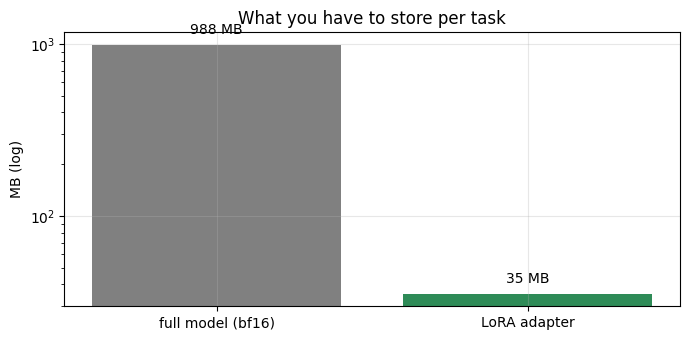

In [ ]:
llm.save_pretrained("qwen-coffee-lora")
adapter_mb = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk("qwen-coffee-lora") for f in fs) / 1e6
tr_llm, tot_llm = count_params(llm)
base_mb_bf16 = (tot_llm - tr_llm) * 2 / 1e6
print(os.listdir("qwen-coffee-lora"))
plt.figure(figsize=(7, 3.5))
plt.bar(["full model (bf16)", "LoRA adapter"], [base_mb_bf16, adapter_mb], color=["gray", "seagreen"])
plt.yscale("log"); plt.ylabel("MB (log)")
for i, v in enumerate([base_mb_bf16, adapter_mb]):
    plt.text(i, v * 1.15, f"{v:,.0f} MB", ha="center")
plt.title("What you have to store per task"); plt.tight_layout(); plt.show()

# To reload later:
#   from peft import PeftModel
#   base = AutoModelForCausalLM.from_pretrained(LLM_NAME); model = PeftModel.from_pretrained(base, "qwen-coffee-lora")

### 🧪 Try it yourself
Write your own messy orders. Try things the training data never contained (new phrasings, typos, an item not in the list) and see where it generalises and where it breaks.

In [ ]:
my_orders = [
    "yo can I get 3 big mochas with almond milk",
    "two regular flat whites, soy milk, cheers",
    "one small cortado please",            # 'cortado' was never in training!
]
for o, a in zip(my_orders, generate(llm, [build_prompt(o) for o in my_orders])):
    print(f"{o:45s} → {a.strip()}")

yo can I get 3 big mochas with almond milk    → {"item": "mocha", "size": "large", "quantity": 3, "milk": "almond"}
two regular flat whites, soy milk, cheers     → {"item": "flat white", "size": "medium", "quantity": 2, "milk": "soy"}
one small cortado please                      → {"item": "cortato", "size": "small", "quantity": 1, "milk": "none"}


## Part 6 — Summary

In [ ]:
print("Classification (DistilBERT, emotion):")
display(pd.DataFrame(RESULTS).T.style.format({"trainable": "{:,.0f}", "total": "{:,.0f}", "time_s": "{:.1f}",
                                              "peak_mem_gb": "{:.2f}", "test_acc": "{:.3f}", "test_f1": "{:.3f}"}))
print("\nLLM SFT (Qwen2.5-0.5B, coffee → JSON):")
display(pd.DataFrame(scores).T.style.format("{:.0%}"))
elapsed()

Classification (DistilBERT, emotion):


,trainable,total,time_s,peak_mem_gb,test_acc,test_f1
Full fine-tune,"66,958,086","66,958,086",20.7,1.81,0.928,0.881
LoRA (r=8),"1,258,758","68,216,844",30.0,2.07,0.918,0.874



LLM SFT (Qwen2.5-0.5B, coffee → JSON):


,valid JSON,item,size,quantity,milk,exact match
zero-shot (no training),0%,0%,0%,0%,0%,0%
few-shot prompt (no training),100%,83%,75%,100%,98%,63%
fine-tuned (LoRA),100%,100%,100%,100%,100%,100%


⏱  9.8 min since the notebook started


### What you should take away
1. **Fine-tuning = continued training on your task.** Pre-trained weights give a huge head start; changes to them are small (Part 2 weight-change plot).
2. **It reshapes representations**, not just the output layer (t-SNE before/after).
3. **LoRA** freezes the model and learns a low-rank update B·A — ~1–2% of the parameters, near-identical accuracy, MB-sized checkpoints.
4. **Learning rate** matters most; LoRA likes ~10× higher LR than full fine-tuning. **Rank** saturates quickly.
5. **Watch validation loss** — when it turns up, you're overfitting; stop early.
6. For **LLMs**: use the model's chat template, mask the prompt out of the loss, and compare against a good *prompting* baseline — fine-tuning wins when you need a precise, reliable format or behaviour.
7. **Narrow fine-tunes can hurt general ability**; mix in general data or keep adapters swappable.

### Where to go next
- **QLoRA:** load the base model in 4-bit (`bitsandbytes`) to fine-tune 7–8B models on this same A100.
- **🤗 TRL `SFTTrainer`:** a production version of the loop you wrote here (packing, chat formats, logging).
- **Bigger, real datasets** and evaluation on held-out *real* user inputs.
- **Preference tuning (DPO)** — teach the model which of two answers is better, not just one correct answer.
- Experiment here: change `r`, `target_modules` (attention-only vs all), the learning rate, or train on 100 vs 2,000 coffee orders and watch the curves move.